# Étapes 4 à 9 : morphologie mathématique et classification

Entrée : les images prétraitées (cerveau, masque, lobe frontal) produites par `scripts/etape3_pretraitement.py`. Le code de morphologie est dans `scripts/morpho.py`.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("../scripts").resolve()))
import morpho
from scipy import ndimage as ndi

DATA = Path("../data/processed")
PRE = DATA / "pretraitement"
TEST = Path("../data/test_synthstrip")
plt.rcParams["figure.dpi"] = 90

## Étape 4 : segmentation

Seuillage d'Otsu à 3 classes (LCR, matière grise, matière blanche), calculé autour du lobe frontal. Exemple sur un enfant (NYU_9907452).

volume recadré : (119, 96, 128) | volume du cerveau : 1549 mL
seuils Otsu : 74 118


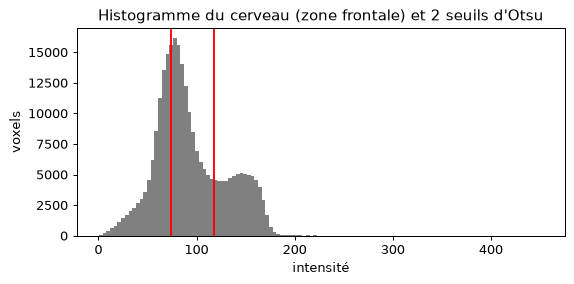

In [2]:
nom = "NYU_9907452"
b, m, f, vol_cerveau = morpho.charger_enfant(TEST / f"{nom}_brain.nii.gz",
                                             TEST / f"{nom}_mask.nii.gz",
                                             TEST / f"{nom}_frontal.nii.gz")
seg = morpho.segmenter(b, m, f)
t1, t2 = seg["seuils"]
print("volume recadré :", b.shape, "| volume du cerveau :", round(vol_cerveau), "mL")
print("seuils Otsu :", round(t1), round(t2))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(b[m & morpho.dilatation(f, 5)], bins=120, color="gray")
for t in (t1, t2):
    ax.axvline(t, color="red")
ax.set_xlabel("intensité"); ax.set_ylabel("voxels"); ax.set_title("Histogramme du cerveau (zone frontale) et 2 seuils d'Otsu")
plt.show()

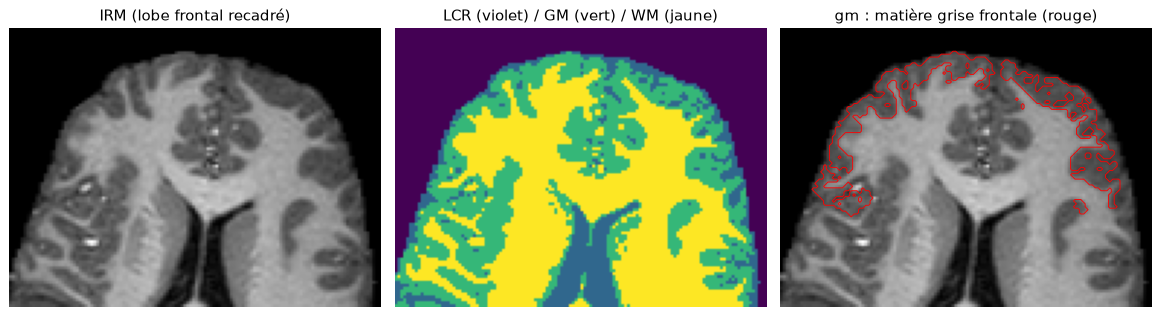

matière grise frontale : 68.061 mL


In [3]:
def coupe(vol, axe=0, pos=None):
    pos = vol.shape[axe] // 2 if pos is None else pos
    return np.take(vol, pos, axis=axe)

# carte des 3 classes : 1 = LCR, 2 = GM, 3 = WM
classes = np.zeros(b.shape, np.uint8)
classes[seg["lcr"]] = 1; classes[seg["gm"]] = 2; classes[seg["wm"]] = 3

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
k = b.shape[0] // 2      # axe 0 de SimpleITK = axe vertical (z)
axes[0].imshow(coupe(b, 0, k), cmap="gray", origin="lower"); axes[0].set_title("IRM (lobe frontal recadré)")
axes[1].imshow(coupe(classes, 0, k), cmap="viridis", origin="lower"); axes[1].set_title("LCR (violet) / GM (vert) / WM (jaune)")
axes[2].imshow(coupe(b, 0, k), cmap="gray", origin="lower")
axes[2].contour(coupe(seg["gm_f"], 0, k).astype(float), levels=[0.5], colors="red", linewidths=0.7)
axes[2].set_title("gm : matière grise frontale (rouge)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()
print("matière grise frontale :", seg["gm_f"].sum() / 1000, "mL")

## Étape 5 : morphologie mathématique

Érosion et dilatation par une boule euclidienne de rayon r, calculées avec la transformée de distance. Comparaison avec `scipy.ndimage.binary_opening` :

In [4]:
from skimage.morphology import ball
gm = seg["gm_f"]
t0 = time.time(); a = ndi.binary_opening(gm, structure=ball(2)); ta = time.time() - t0
t0 = time.time(); e = morpho.ouverture(gm, 2.0); te = time.time() - t0
print(f"ndi.binary_opening(ball(2)) : {ta:.1f} s  |  ouverture par EDT : {te:.1f} s")
print("voxels différents :", (a != e).sum(), "sur", gm.sum(), "(différence due à la discrétisation de ball())")

ndi.binary_opening(ball(2)) : 0.0 s  |  ouverture par EDT : 0.4 s
voxels différents : 0 sur 68061 (différence due à la discrétisation de ball())


### 5.1 Granulométrie par ouvertures

Volume de matière grise restant après ouverture par des boules de rayon croissant : distribution de l'épaisseur locale.

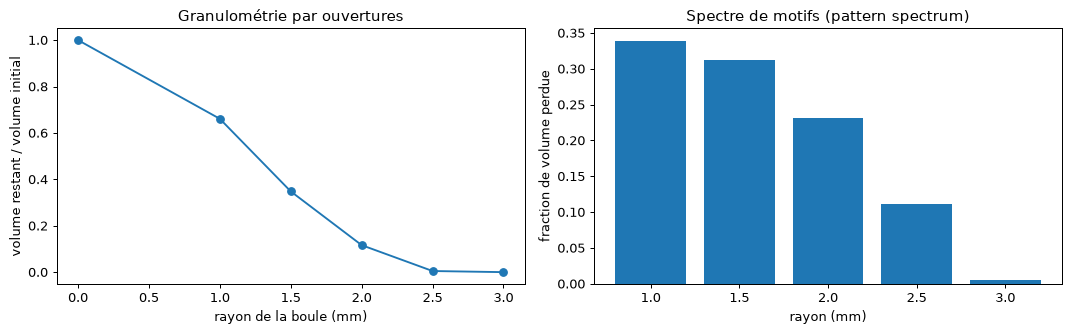

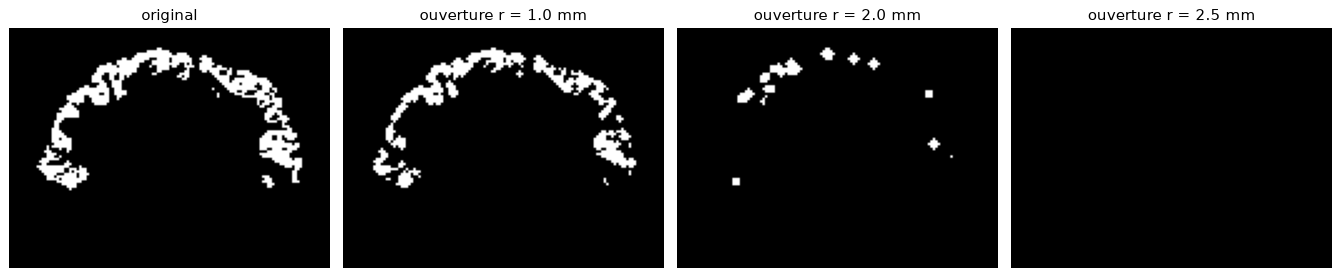

In [5]:
restes, spectre = morpho.granulometrie_ouvertures(gm)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot([0] + morpho.RAYONS_OUV, restes, "o-")
axes[0].set_xlabel("rayon de la boule (mm)"); axes[0].set_ylabel("volume restant / volume initial")
axes[0].set_title("Granulométrie par ouvertures")
axes[1].bar([str(r) for r in morpho.RAYONS_OUV], spectre)
axes[1].set_xlabel("rayon (mm)"); axes[1].set_ylabel("fraction de volume perdue")
axes[1].set_title("Spectre de motifs (pattern spectrum)")
plt.tight_layout(); plt.show()

k = b.shape[0] // 2
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for a, r in zip(axes, [0, 1.0, 2.0, 2.5]):
    o = gm if r == 0 else morpho.ouverture(gm, r)
    a.imshow(coupe(o, 0, k), cmap="gray", origin="lower"); a.axis("off")
    a.set_title("original" if r == 0 else f"ouverture r = {r} mm")
plt.tight_layout(); plt.show()

### 5.2 Granulométrie par fermetures

Volume comblé par la fermeture du tissu (matière grise + blanche) : largeur des sillons.

{'r=1.0': np.float64(0.068), 'r=2.0': np.float64(0.141), 'r=3.0': np.float64(0.204), 'r=4.0': np.float64(0.225)}


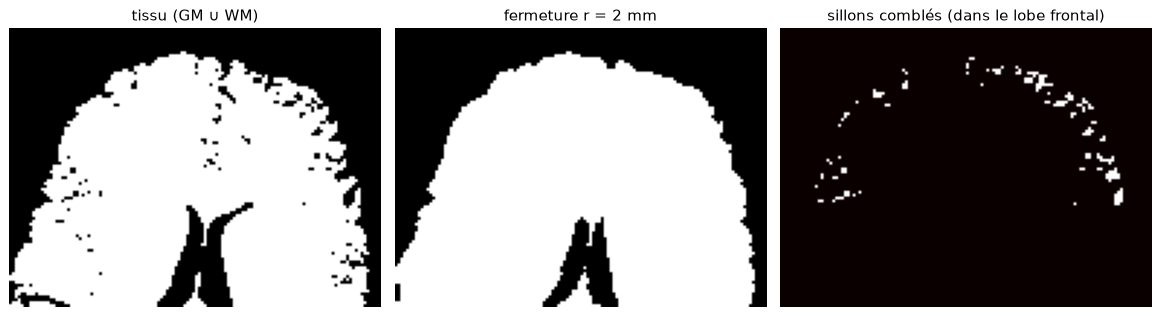

In [6]:
T = seg["gm"] | seg["wm"]
rempli, _ = morpho.granulometrie_fermetures(T, f)
print({f"r={r}": round(v, 3) for r, v in zip(morpho.RAYONS_FERM, rempli)})

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
k = b.shape[0] // 2
axes[0].imshow(coupe(T, 0, k), cmap="gray", origin="lower"); axes[0].set_title("tissu (GM ∪ WM)")
clo = morpho.fermeture(T, 2.0)
axes[1].imshow(coupe(clo, 0, k), cmap="gray", origin="lower"); axes[1].set_title("fermeture r = 2 mm")
axes[2].imshow(coupe(clo & ~T & f, 0, k), cmap="hot", origin="lower"); axes[2].set_title("sillons comblés (dans le lobe frontal)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### 5.3 Squelette et transformée de distance

Épaisseur corticale lue sur le squelette (2 × distance au bord).

{'ep_moy': 2.303, 'ep_std': 0.549, 'ep_p90': 2.828, 'sq_ratio': 0.168, 'sq_extremites': 11.961, 'sq_jonctions': 747.25}


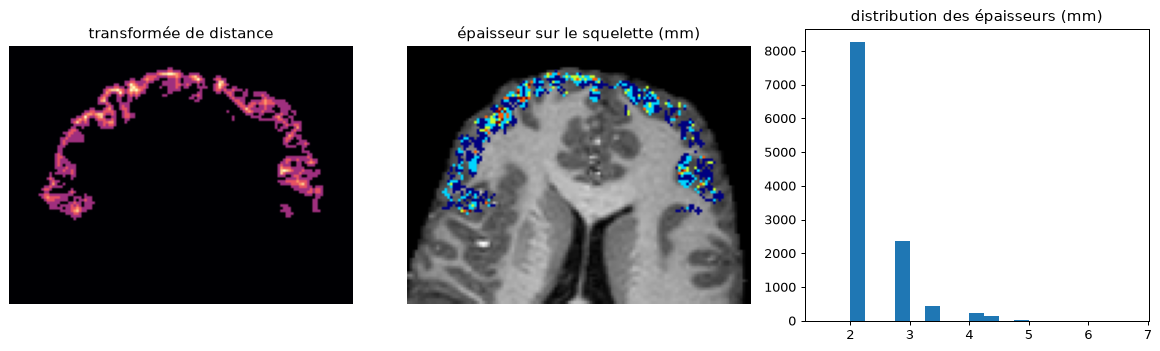

In [7]:
stats, sq, dt = morpho.squelette_epaisseur(gm)
print({k: round(float(v), 3) for k, v in stats.items()})

ep = np.where(sq, 2 * dt, np.nan)
k = b.shape[0] // 2
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(coupe(dt, 0, k), cmap="magma", origin="lower"); axes[0].set_title("transformée de distance")
axes[1].imshow(coupe(b, 0, k), cmap="gray", origin="lower")
axes[1].imshow(np.ma.masked_invalid(np.nanmax(ep[k-3:k+4], axis=0)), cmap="jet", origin="lower")
axes[1].set_title("épaisseur sur le squelette (mm)")
axes[2].hist(2 * dt[sq], bins=np.arange(1.5, 7, 0.25)); axes[2].set_title("distribution des épaisseurs (mm)")
for a in axes[:2]: a.axis("off")
plt.tight_layout(); plt.show()

### 5.4 Gradient morphologique, top-hat noir, nombre d'Euler

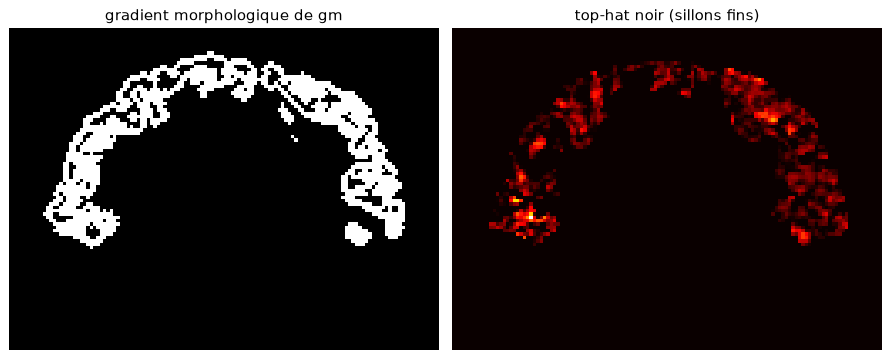

30 descripteurs pour cet enfant :
vol_frontal_frac       0.098
gm_frac                0.448
wm_frac                0.215
lcr_frac               0.335
ouv_reste_r1.0         0.661
ouv_reste_r1.5         0.348
ouv_reste_r2.0         0.116
ouv_reste_r2.5         0.005
ouv_reste_r3.0         0.000
ouv_spectre_r1.0       0.339
ouv_spectre_r1.5       0.313
ouv_spectre_r2.0       0.232
ouv_spectre_r2.5       0.112
ouv_spectre_r3.0       0.005
ferm_rempli_r1.0       0.068
ferm_rempli_r2.0       0.141
ferm_rempli_r3.0       0.204
ferm_rempli_r4.0       0.225
ep_moy                 2.303
ep_std                 0.549
ep_p90                 2.828
sq_ratio               0.168
sq_extremites         11.961
sq_jonctions         747.250
gm_surface_volume      1.618
gyrification           3.631
tophat_noir_moy        0.051
tophat_noir_p90        0.135
euler_gm              -8.772
contraste_gm_wm        0.621


In [8]:
grad = morpho.gradient_morpho(gm)
bb = b / np.median(b[seg["wm"] & f])
th = ndi.grey_closing(bb, footprint=ball(2)) - bb
k = b.shape[0] // 2
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(coupe(grad, 0, k), cmap="gray", origin="lower"); axes[0].set_title("gradient morphologique de gm")
axes[1].imshow(coupe(th * f, 0, k), cmap="hot", origin="lower"); axes[1].set_title("top-hat noir (sillons fins)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

d = morpho.descripteurs(b, m, f, vol_cerveau, seg)
print(len(d), "descripteurs pour cet enfant :")
print(pd.Series(d).round(3).to_string())

## Descripteurs de tous les enfants

Calculés par `scripts/etape45_descripteurs.py`. Pittsburgh est exclu de la classification (aucun enfant ADHD).

In [9]:
desc = pd.read_csv(DATA / "descripteurs.csv", dtype={"subject_id": str})
table = pd.read_csv(DATA / "table_propre.csv", dtype={"subject_id": str})
qc = pd.read_csv(PRE / "resultats.csv", dtype={"subject_id": str})[["subject_id", "dice_recalage", "vol_cerveau_ml"]]

df = table.merge(desc.drop(columns="site"), on="subject_id").merge(qc, on="subject_id")
# contrôle qualité de l'étape 3
df = df[(df["dice_recalage"] >= 0.85) & df["vol_cerveau_ml"].between(900, 2000)]
print("enfants avec descripteurs :", len(df))

FEATS = [c for c in desc.columns if c not in ("subject_id", "site")]
FEATS = [c for c in FEATS if df[c].std() > 1e-9]          # retire les colonnes constantes
print(len(FEATS), "descripteurs morphologiques")

dfc = df[df["site"] != "Pittsburgh"].reset_index(drop=True)
print("\nenfants utilisés pour la classification :", len(dfc))
print(pd.crosstab(dfc["site"], dfc["adhd"], margins=True))

enfants avec descripteurs : 649
30 descripteurs morphologiques

enfants utilisés pour la classification : 571
adhd          0    1  All
site                     
KKI          60   22   82
NYU          96  114  210
NeuroIMAGE   23   25   48
OHSU         60   41  101
Peking_1     87   43  130
All         326  245  571


### Vérification : lien des descripteurs avec l'âge et le diagnostic

                   rho_age  p_age  d_cohen_adhd  p_adhd
descripteur                                            
ouv_spectre_r2.0     0.546  0.000        -0.024   0.898
ouv_reste_r3.0      -0.397  0.000        -0.121   0.384
tophat_noir_p90      0.387  0.000        -0.227   0.002
wm_frac              0.385  0.000         0.004   0.970
ouv_reste_r2.5      -0.349  0.000        -0.186   0.050
ouv_spectre_r3.0    -0.333  0.000        -0.201   0.032
tophat_noir_moy      0.303  0.000        -0.130   0.065
sq_jonctions        -0.294  0.000         0.278   0.001
ep_std              -0.271  0.000        -0.211   0.013
sq_ratio            -0.260  0.000         0.334   0.000
ouv_reste_r2.0      -0.252  0.000        -0.198   0.017
gm_frac             -0.247  0.000        -0.178   0.045
ouv_spectre_r1.5     0.224  0.000         0.193   0.019
euler_gm            -0.210  0.000         0.096   0.174
ep_p90              -0.206  0.000        -0.202   0.026
ep_moy              -0.192  0.000        -0.222 

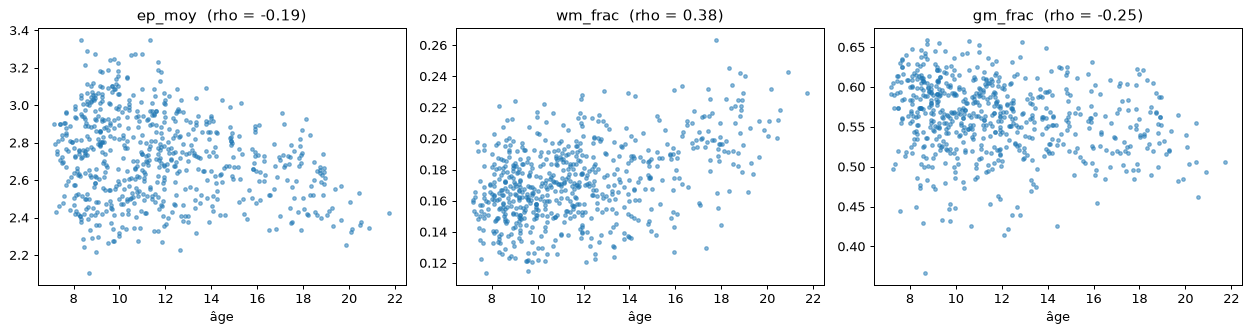

In [10]:
from scipy import stats as st
lignes = []
for c in FEATS:
    r, p = st.spearmanr(df[c], df["age"])
    ctrl, adhd = dfc.loc[dfc["adhd"] == 0, c], dfc.loc[dfc["adhd"] == 1, c]
    sp = np.sqrt((ctrl.var() + adhd.var()) / 2)
    lignes.append({"descripteur": c, "rho_age": r, "p_age": p,
                   "d_cohen_adhd": (adhd.mean() - ctrl.mean()) / sp,
                   "p_adhd": st.mannwhitneyu(adhd, ctrl).pvalue})
uni = pd.DataFrame(lignes).set_index("descripteur")
print(uni.sort_values("p_age").round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip(axes, ["ep_moy", "wm_frac", "gm_frac"]):
    a.scatter(df["age"], df[c], s=8, alpha=0.5)
    a.set_xlabel("âge"); a.set_title(f"{c}  (rho = {uni.loc[c, 'rho_age']:.2f})")
plt.tight_layout(); plt.show()

## Étape 6 : harmonisation par site

Z-score par site, puis retrait de l'âge et du sexe. Les deux sont appris uniquement sur les données d'entraînement de chaque pli.

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, LeaveOneGroupOut, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, confusion_matrix


class Harmonise(BaseEstimator, TransformerMixin):
    # entrée : DataFrame avec les descripteurs + 'site', 'age', 'sexe' ; sortie : résidus des descripteurs
    def __init__(self, feats):
        self.feats = feats

    def _par_site(self, X):
        Z = X[self.feats].astype(float).copy()
        for s, idx in X.groupby("site").groups.items():
            if s in self.stats_:
                mu, sd = self.stats_[s]
            else:                       # site jamais vu : ses propres stats (sans étiquettes)
                mu, sd = X.loc[idx, self.feats].mean(), X.loc[idx, self.feats].std()
            Z.loc[idx] = (X.loc[idx, self.feats] - mu) / sd.fillna(1).replace(0, 1)   # site d'un seul enfant : sd non défini
        return Z

    def _cov(self, X):
        return np.c_[X["age"].values, X["sexe"].fillna(X["sexe"].mean()).values]

    def fit(self, X, y=None):
        self.stats_ = {s: (g[self.feats].mean(), g[self.feats].std()) for s, g in X.groupby("site")}
        Z = self._par_site(X)
        self.reg_ = LinearRegression().fit(self._cov(X), Z.values)
        return self

    def transform(self, X):
        Z = self._par_site(X)
        return Z.values - self.reg_.predict(self._cov(X))


VARS_A = ["age", "sexe", "iq", "handedness_num"]

## Étape 7 : modèles

| Modèle | Entrées | Classifieur |
|---|---|---|
| A | âge, sexe, QI, latéralité | régression logistique |
| B-LR, B-SVM, B-RF | 30 descripteurs morphologiques | régression logistique, SVM, forêt aléatoire |
| D | descripteurs + variables de A | régression logistique |

In [12]:
def modele_A(avec_site=True):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    tr = [("num", num, VARS_A)]
    if avec_site:
        tr.append(("site", OneHotEncoder(handle_unknown="ignore"), ["site"]))
    return Pipeline([("prep", ColumnTransformer(tr)),
                     ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))])

def modele_B(clf):
    return Pipeline([("harm", Harmonise(FEATS)), ("sc", StandardScaler()), ("clf", clf)])

class HarmonisePlusA(BaseEstimator, TransformerMixin):
    # descripteurs harmonisés + âge, sexe, QI, latéralité (imputés sur l'entraînement)
    def __init__(self, feats):
        self.feats = feats
    def fit(self, X, y=None):
        self.h_ = Harmonise(self.feats).fit(X)
        self.imp_ = SimpleImputer(strategy="median").fit(X[VARS_A])
        return self
    def transform(self, X):
        return np.c_[self.h_.transform(X), self.imp_.transform(X[VARS_A])]

MODELES = {
    "A baseline": modele_A(),
    "B-LR morpho": modele_B(LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)),
    "B-SVM morpho": modele_B(SVC(C=1.0, kernel="rbf", gamma="scale", class_weight="balanced")),
    "B-RF morpho": modele_B(RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                   class_weight="balanced", random_state=0, n_jobs=-1)),
    "D morpho + A": Pipeline([("h", HarmonisePlusA(FEATS)), ("sc", StandardScaler()),
                              ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))]),
}

def score(model, X):
    return (model.decision_function(X) if hasattr(model, "decision_function")
            else model.predict_proba(X)[:, 1])

## Étape 8 : évaluation

Balanced accuracy et AUC, validation croisée 5 plis × 10 répétitions.

In [13]:
X, y = dfc, dfc["adhd"].values
strate = dfc["site"] + "_" + dfc["adhd"].astype(str)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)

def evaluer_cv(model):
    ba, auc = [], []
    for tr, te in cv.split(X, strate):
        m = clone(model).fit(X.iloc[tr], y[tr])
        ba.append(balanced_accuracy_score(y[te], m.predict(X.iloc[te])))
        auc.append(roc_auc_score(y[te], score(m, X.iloc[te])))
    return np.array(ba), np.array(auc)

t0 = time.time()
res_cv = {}
for nom_m, mod in MODELES.items():
    ba, auc = evaluer_cv(mod)
    res_cv[nom_m] = {"BA moy": ba.mean(), "BA std": ba.std(), "AUC moy": auc.mean(), "AUC std": auc.std()}
res_cv = pd.DataFrame(res_cv).T.round(3)
print(f"Validation croisée 5 plis x 10 répétitions ({len(dfc)} enfants, {time.time()-t0:.0f} s)")
print(res_cv)

Validation croisée 5 plis x 10 répétitions (571 enfants, 73 s)
              BA moy  BA std  AUC moy  AUC std
A baseline     0.692   0.042    0.746    0.035
B-LR morpho    0.581   0.043    0.607    0.045
B-SVM morpho   0.600   0.038    0.637    0.042
B-RF morpho    0.598   0.034    0.628    0.038
D morpho + A   0.673   0.039    0.732    0.040


### Leave-one-site-out

Entraînement sur 4 sites, test sur le 5e.

In [14]:
logo = LeaveOneGroupOut()
modeles_loso = dict(MODELES); modeles_loso["A baseline"] = modele_A(avec_site=False)
lignes, par_site = [], []
for nom_m, mod in modeles_loso.items():
    pred, sc_ = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in logo.split(X, y, groups=dfc["site"]):
        m = clone(mod).fit(X.iloc[tr], y[tr])
        pred[te], sc_[te] = m.predict(X.iloc[te]), score(m, X.iloc[te])
        site = dfc["site"].iloc[te[0]]
        if len(set(y[te])) == 2:
            par_site.append({"modèle": nom_m, "site": site, "AUC": roc_auc_score(y[te], sc_[te])})
    lignes.append({"modèle": nom_m, "BA": balanced_accuracy_score(y, pred), "AUC": roc_auc_score(y, sc_)})
res_loso = pd.DataFrame(lignes).set_index("modèle").round(3)
print(res_loso)
print()
print(pd.DataFrame(par_site).pivot(index="modèle", columns="site", values="AUC").round(2))

                 BA    AUC
modèle                    
A baseline    0.659  0.694
B-LR morpho   0.560  0.603
B-SVM morpho  0.538  0.579
B-RF morpho   0.575  0.604
D morpho + A  0.672  0.719

site           KKI   NYU  NeuroIMAGE  OHSU  Peking_1
modèle                                              
A baseline    0.56  0.68        0.69  0.68      0.88
B-LR morpho   0.54  0.60        0.65  0.66      0.59
B-RF morpho   0.51  0.63        0.55  0.66      0.59
B-SVM morpho  0.49  0.59        0.43  0.68      0.62
D morpho + A  0.56  0.71        0.72  0.74      0.84


### Test de permutation

Étiquettes mélangées 200 fois à l'intérieur de chaque site.

B-LR morpho    AUC réelle = 0.611 | hasard : 0.503 ± 0.034 | p = 0.005 (119 s)


D morpho + A   AUC réelle = 0.731 | hasard : 0.520 ± 0.028 | p = 0.005 (123 s)


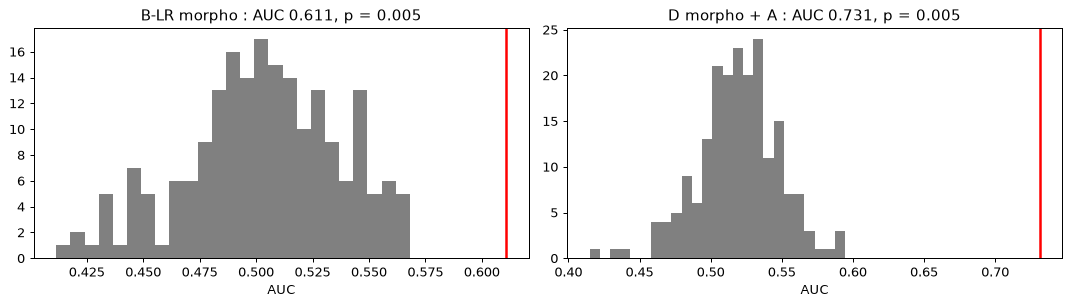

In [15]:
rng = np.random.default_rng(0)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def auc_cv(model, yy):
    s = np.zeros(len(yy))
    for tr, te in cv5.split(X, dfc["site"] + "_" + pd.Series(yy).astype(str)):
        m = clone(model).fit(X.iloc[tr], yy[tr])
        s[te] = score(m, X.iloc[te])
    return roc_auc_score(yy, s)

def permuter_par_site(yy):
    yp = yy.copy()
    for idx in dfc.groupby("site").indices.values():
        yp[idx] = rng.permutation(yp[idx])
    return yp

N_PERM = 200
resultats_perm = {}
for nom_m in ["B-LR morpho", "D morpho + A"]:
    t0 = time.time()
    vrai = auc_cv(MODELES[nom_m], y)
    nul = np.array([auc_cv(MODELES[nom_m], permuter_par_site(y)) for _ in range(N_PERM)])
    p = (1 + (nul >= vrai).sum()) / (1 + N_PERM)
    resultats_perm[nom_m] = (vrai, nul, p)
    print(f"{nom_m:14s} AUC réelle = {vrai:.3f} | hasard : {nul.mean():.3f} ± {nul.std():.3f} | p = {p:.3f} ({time.time()-t0:.0f} s)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for a, (nom_m, (vrai, nul, p)) in zip(axes, resultats_perm.items()):
    a.hist(nul, bins=25, color="gray"); a.axvline(vrai, color="red", lw=2)
    a.set_title(f"{nom_m} : AUC {vrai:.3f}, p = {p:.3f}"); a.set_xlabel("AUC")
plt.tight_layout(); plt.show()

### Comparaison des modèles et matrice de confusion

In [16]:
ablation = pd.concat({"CV répétée": res_cv[["BA moy", "AUC moy"]],
                      "Leave-one-site-out": res_loso.rename(columns={"BA": "BA moy", "AUC": "AUC moy"})}, axis=1)
print(ablation)

pred = np.zeros(len(y))
for tr, te in logo.split(X, y, groups=dfc["site"]):
    pred[te] = clone(MODELES["B-LR morpho"]).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
cm = confusion_matrix(y, pred)
print("\nMatrice de confusion B-LR (leave-one-site-out) :")
print(pd.DataFrame(cm, index=["vrai contrôle", "vrai ADHD"], columns=["prédit contrôle", "prédit ADHD"]))
print(f"sensibilité = {cm[1,1]/cm[1].sum():.2f} | spécificité = {cm[0,0]/cm[0].sum():.2f}")

n_test = len(y) / 5
print(f"\nRepère : avec ~{n_test:.0f} enfants par pli de test, l'écart-type d'un score au hasard est ≈ {np.sqrt(0.25/n_test):.3f}")

             CV répétée         Leave-one-site-out        
                 BA moy AUC moy             BA moy AUC moy
A baseline        0.692   0.746              0.659   0.694
B-LR morpho       0.581   0.607              0.560   0.603
B-SVM morpho      0.600   0.637              0.538   0.579
B-RF morpho       0.598   0.628              0.575   0.604
D morpho + A      0.673   0.732              0.672   0.719



Matrice de confusion B-LR (leave-one-site-out) :
               prédit contrôle  prédit ADHD
vrai contrôle              188          138
vrai ADHD                  112          133
sensibilité = 0.54 | spécificité = 0.58

Repère : avec ~114 enfants par pli de test, l'écart-type d'un score au hasard est ≈ 0.047


### Prédictions par enfant (modèle D, leave-one-site-out)

Exemple : les 15 premiers enfants de OHSU
 enfant site  âge     vrai  proba_ADHD   prédit  correct
9499804 OHSU  8.2 contrôle        0.44 contrôle     True
8720244 OHSU 10.3     ADHD        0.72     ADHD     True
8218392 OHSU  8.3 contrôle        0.69     ADHD    False
8064456 OHSU  9.2 contrôle        0.35 contrôle     True
7333005 OHSU  9.0     ADHD        0.65     ADHD     True
6953386 OHSU 11.8     ADHD        0.26 contrôle    False
6592761 OHSU  7.6 contrôle        0.33 contrôle     True
5302451 OHSU 11.3     ADHD        0.42 contrôle    False
4219416 OHSU  8.2 contrôle        0.35 contrôle     True
4072305 OHSU  9.2     ADHD        0.44 contrôle    False
4046678 OHSU  8.6 contrôle        0.08 contrôle     True
4016887 OHSU  9.1     ADHD        0.51     ADHD     True
3869075 OHSU  8.7 contrôle        0.38 contrôle     True
3812101 OHSU  7.8 contrôle        0.49 contrôle     True
3684229 OHSU  8.8     ADHD        0.21 contrôle    False

Bonnes réponses par hôpital (chaque hôpital j

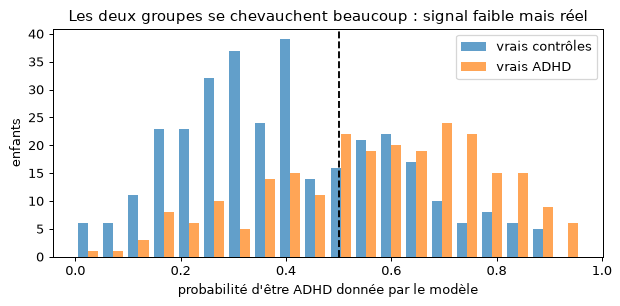

In [17]:
lignes = []
for tr, te in logo.split(X, y, groups=dfc["site"]):
    m = clone(MODELES["D morpho + A"]).fit(X.iloc[tr], y[tr])
    proba = m.predict_proba(X.iloc[te])[:, 1]          # probabilité d'être ADHD
    for i, p in zip(te, proba):
        lignes.append({"enfant": dfc["subject_id"].iloc[i], "site": dfc["site"].iloc[i],
                       "âge": round(dfc["age"].iloc[i], 1),
                       "vrai": "ADHD" if y[i] == 1 else "contrôle",
                       "proba_ADHD": round(p, 2),
                       "prédit": "ADHD" if p > 0.5 else "contrôle"})
verif = pd.DataFrame(lignes)
verif["correct"] = verif["vrai"] == verif["prédit"]
verif.to_csv(DATA / "predictions_par_enfant.csv", index=False)

print("Exemple : les 15 premiers enfants de OHSU")
print(verif[verif["site"] == "OHSU"].head(15).to_string(index=False))
print("\nBonnes réponses par hôpital (chaque hôpital jamais vu par le modèle) :")
print(verif.groupby("site")["correct"].agg(["sum", "count", "mean"]).round(2)
      .rename(columns={"sum": "bonnes", "count": "enfants", "mean": "taux"}))
print(f"\nTOTAL : {verif['correct'].sum()} / {len(verif)} = {verif['correct'].mean():.0%} de bonnes réponses (hasard ≈ 50 %)")

# plus le modèle est sûr de lui, plus il a raison ?
verif["confiance"] = (verif["proba_ADHD"] - 0.5).abs()
sur = verif[verif["confiance"] > 0.25]
print(f"Quand le modèle est très sûr (proba < 0,25 ou > 0,75) : {sur['correct'].mean():.0%} de bonnes réponses sur {len(sur)} enfants")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([verif.loc[verif["vrai"] == "contrôle", "proba_ADHD"], verif.loc[verif["vrai"] == "ADHD", "proba_ADHD"]],
        bins=20, label=["vrais contrôles", "vrais ADHD"], alpha=0.7)
ax.axvline(0.5, color="black", ls="--")
ax.set_xlabel("probabilité d'être ADHD donnée par le modèle"); ax.set_ylabel("enfants"); ax.legend()
ax.set_title("Les deux groupes se chevauchent beaucoup : signal faible mais réel")
plt.tight_layout(); plt.show()

## Étape 9 : interprétation

Coefficients de la régression logistique et stabilité par bootstrap (200 tirages).

                    coef  IC95_bas  IC95_haut  même_signe_%
euler_gm           0.260     0.003      0.475          97.5
tophat_noir_p90   -0.214    -0.398     -0.030          98.0
ep_std            -0.197    -0.476      0.052          93.0
vol_frontal_frac  -0.184    -0.355      0.003          97.0
wm_frac           -0.183    -0.379      0.045          94.5
sq_ratio          -0.154    -0.387      0.110          88.0
gm_surface_volume  0.131    -0.031      0.256          94.0
ferm_rempli_r3.0   0.119    -0.128      0.333          87.0
sq_jonctions       0.114    -0.101      0.370          78.5
ouv_reste_r3.0     0.114    -0.119      0.338          88.0
lcr_frac          -0.108    -0.291      0.078          79.5
ferm_rempli_r1.0   0.101    -0.123      0.345          82.5


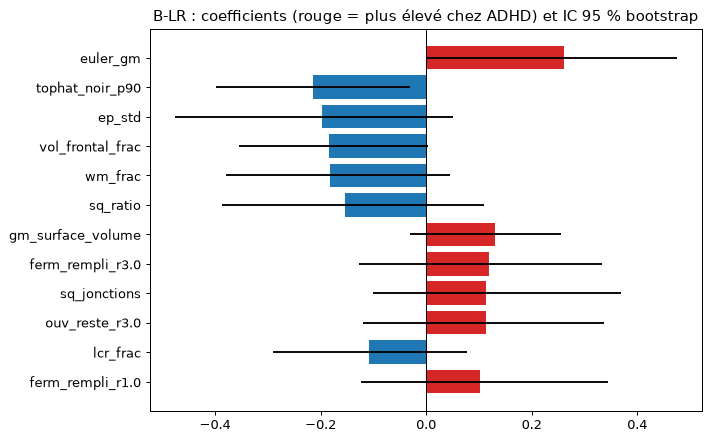

In [18]:
final = clone(MODELES["B-LR morpho"]).fit(X, y)
coefs = pd.Series(final.named_steps["clf"].coef_[0], index=FEATS)

boot = []
for i in range(200):
    idx = rng.choice(len(y), len(y), replace=True)
    mb = clone(MODELES["B-LR morpho"]).fit(X.iloc[idx], y[idx])
    boot.append(mb.named_steps["clf"].coef_[0])
boot = np.array(boot)
stab = pd.DataFrame({"coef": coefs,
                     "IC95_bas": np.percentile(boot, 2.5, axis=0),
                     "IC95_haut": np.percentile(boot, 97.5, axis=0),
                     "même_signe_%": (np.sign(boot) == np.sign(coefs.values)).mean(axis=0) * 100},
                    index=FEATS)
stab = stab.reindex(stab["coef"].abs().sort_values(ascending=False).index)
print(stab.round(3).head(12).to_string())

top = stab.head(12)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top["coef"][::-1],
        xerr=[(top["coef"] - top["IC95_bas"]).clip(lower=0)[::-1], (top["IC95_haut"] - top["coef"]).clip(lower=0)[::-1]],
        color=["tab:red" if c > 0 else "tab:blue" for c in top["coef"][::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("B-LR : coefficients (rouge = plus élevé chez ADHD) et IC 95 % bootstrap")
plt.tight_layout(); plt.show()

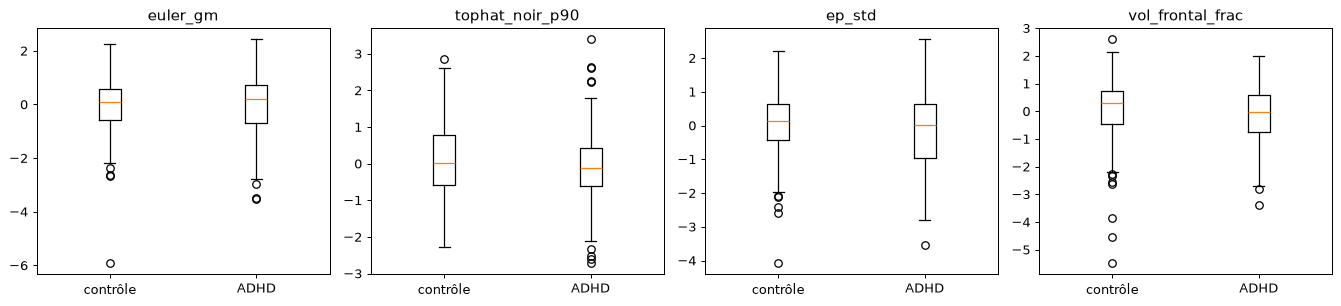

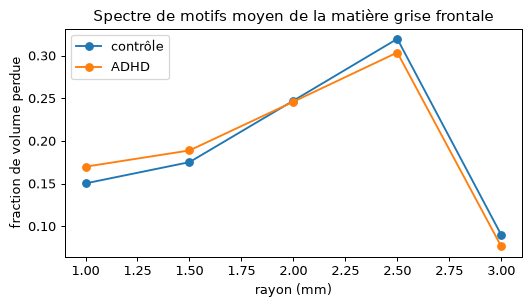

In [19]:
# comparaison des groupes sur les 4 descripteurs les plus importants (valeurs harmonisées + âge/sexe régressés)
H = pd.DataFrame(Harmonise(FEATS).fit(X).transform(X), columns=FEATS)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for a, c in zip(axes, stab.index[:4]):
    a.boxplot([H.loc[y == 0, c], H.loc[y == 1, c]], tick_labels=["contrôle", "ADHD"])
    a.set_title(c)
plt.tight_layout(); plt.show()

# spectre de motifs moyen par groupe
cols = [f"ouv_spectre_r{r}" for r in morpho.RAYONS_OUV]
moy = dfc.groupby("adhd")[cols].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
for g, nom_g in [(0, "contrôle"), (1, "ADHD")]:
    ax.plot(morpho.RAYONS_OUV, moy.loc[g], "o-", label=nom_g)
ax.set_xlabel("rayon (mm)"); ax.set_ylabel("fraction de volume perdue"); ax.legend()
ax.set_title("Spectre de motifs moyen de la matière grise frontale")
plt.tight_layout(); plt.show()

In [20]:
# sauvegarde des résultats pour le rapport
sortie = DATA / "resultats_classification"
sortie.mkdir(exist_ok=True)
res_cv.to_csv(sortie / "cv_repetee.csv")
res_loso.to_csv(sortie / "leave_one_site_out.csv")
stab.to_csv(sortie / "coefficients_B-LR.csv")
uni.to_csv(sortie / "descripteurs_univarie.csv")
pd.DataFrame({k: {"AUC": v[0], "AUC_hasard": v[1].mean(), "p": v[2]} for k, v in resultats_perm.items()}).T.to_csv(sortie / "permutation.csv")
print("enregistré dans", sortie.resolve())
print(f"\nRÉSUMÉ ({len(dfc)} enfants, {len(FEATS)} descripteurs morphologiques)")
print(ablation.round(3))

enregistré dans C:\Users\monta\adhd-project\data\processed\resultats_classification

RÉSUMÉ (571 enfants, 30 descripteurs morphologiques)
             CV répétée         Leave-one-site-out        
                 BA moy AUC moy             BA moy AUC moy
A baseline        0.692   0.746              0.659   0.694
B-LR morpho       0.581   0.607              0.560   0.603
B-SVM morpho      0.600   0.637              0.538   0.579
B-RF morpho       0.598   0.628              0.575   0.604
D morpho + A      0.673   0.732              0.672   0.719


## Conclusion

| Modèle | BA (site jamais vu) | AUC (site jamais vu) |
|---|---|---|
| A : âge, sexe, QI | 0,66 | 0,69 |
| B-LR : morphologie | 0,56 | 0,60 |
| D : morphologie + A | 0,67 | 0,72 |

- La morphologie seule donne un signal faible mais significatif (permutation : p = 0,005).
- Le meilleur modèle sur un site jamais vu est D (67 % de bonnes réponses).
- Descripteurs les plus stables : fraction frontale (plus petite chez les ADHD), top-hat noir, nombre d'Euler.

Limites : segmentation par seuils, recalage affine seulement, harmonisation simple (pas de ComBat), forte variation entre sites (49 % à KKI, 78 % à Peking_1).